# Thresholding lab
### Compare global (T = 127), Otsu, adaptive-mean and adaptive-Gaussian thresholding on an unevenly lit document photo.

In [2]:
import cv2
import matplotlib.pyplot as plt

(945, 736)


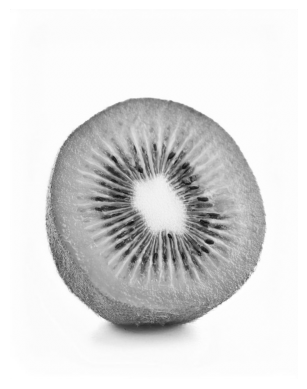

In [11]:
gray=cv2.imread('pic.jpg',0)
print(gray.shape)

plt.imshow(gray,cmap='gray')
plt.axis('off')
plt.show()

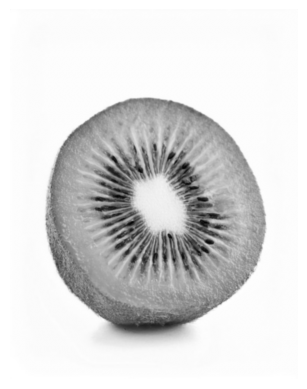

In [12]:
blur=cv2.GaussianBlur(gray,(5,5),0)
plt.imshow(blur,cmap='gray')
plt.axis('off')
plt.show()

### the 4 methods 

In [14]:
# global (T = 127)
_,global_t= cv2.threshold(blur,127,255,cv2.THRESH_BINARY)

#Otsu
otsu_value,otsu= cv2.threshold(blur,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)

# adaptive-mean
adpt_mean=cv2.adaptiveThreshold(blur,255,cv2.ADAPTIVE_THRESH_MEAN_C,cv2.THRESH_BINARY,11,2)

#adaptive_gaussian
adpt_gaussian=cv2.adaptiveThreshold(blur,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,11,2)

print('otsu value:',otsu_value)

otsu value: 201.0


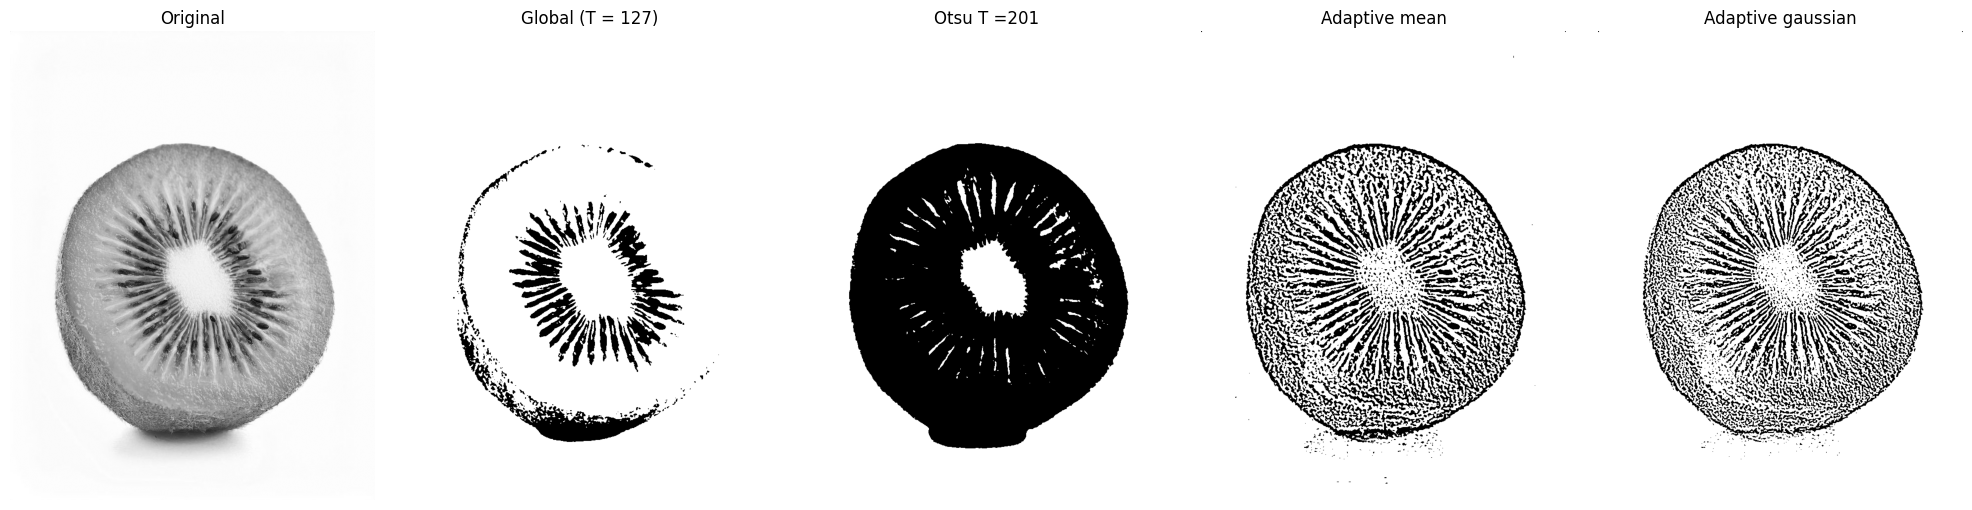

In [19]:
fig,axes=plt.subplots(1,5,figsize=(20,5))
values=[gray,global_t,otsu,adpt_mean,adpt_gaussian]
titles=['Original','Global (T = 127)','Otsu T ='+str(int(otsu_value)),'Adaptive mean','Adaptive gaussian']

for ax,v,ti in zip(axes,values,titles):
    ax.imshow(v,cmap='gray')
    ax.set_title(ti)
    ax.axis('off')

plt.tight_layout()
plt.savefig('13_Figure.jpg')
plt.show()